# African Wildlife Dataset – Exploration

**Projet :** Détection et comptage de la faune africaine (YOLOv8n)
**Responsable de cette partie :** LEMNAOUIR Rachida
**Étape :** 1 – Exploration et analyse du dataset

**Objectif :** explorer le dataset, vérifier les annotations, analyser la distribution des classes, étudier la taille des objets et définir une règle « petit / grand objet » à partir de la validation.

**Livrable :** ce notebook + les graphiques + les fichiers `annotations_all.csv` et `size_rule.json` (partagés avec l'équipe via Google Drive).

### Plan du notebook
1. Source et description du dataset
2. Préparation de l'environnement
3. Structure et partitions officielles
4. Chargement des annotations
5. Contrôle qualité des annotations
6. Distribution des classes
7. Taille des bounding boxes
8. Règle petit / grand objet (définie sur la validation)
9. Exemples annotés
10. Conclusion de l'Étape 1

# 1. Source et description du dataset

**Dataset :** African Wildlife (Ultralytics)
**Lien :** https://docs.ultralytics.com/datasets/detect/african-wildlife

| Élément | Valeur |
|---|---|
| Images totales | 1 504 |
| Classes | 4 (buffalo, elephant, rhino, zebra) |
| Entraînement / Validation / Test | 1 052 / 225 / 227 |
| Format des annotations | YOLO (une ligne par objet : `classe x_centre y_centre largeur hauteur`, valeurs entre 0 et 1) |

**Règle du projet :** on garde les partitions officielles. On ne crée aucun nouveau découpage.

**Pourquoi cette partie ?** Avant d'entraîner un modèle, il faut connaître ses données. Cela évite les erreurs et aide à expliquer les résultats plus tard.

# 2. Préparation de l'environnement

Cette cellule :
- monte Google Drive (pour partager les résultats avec l'équipe),
- définit les paramètres du projet (chemins, classes, graine aléatoire),
- télécharge le dataset **seulement s'il n'existe pas déjà** (on peut donc relancer la cellule sans problème).

**À quoi ça sert ensuite ?** Tous les notebooks de l'équipe (modèle A, modèle B, évaluation) utiliseront les mêmes chemins et le même dataset.

In [13]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# ---- Dépôt GitHub ----
REPO_URL = "https://github.com/YSSFM/African_Wildlife_Detection_and_Counting_Project.git"
REPO_DIR = "/content/African_Wildlife_Detection_and_Counting_Project"
if not os.path.exists(REPO_DIR):
    !git clone -q {REPO_URL} {REPO_DIR}
OUT = f"{REPO_DIR}/results"
os.makedirs(OUT, exist_ok=True)

# ---- Paramètres du projet ---- (nafs ma kan)
ROOT = "/content/african-wildlife"
SPLITS = {"train": "train", "val": "val", "test": "test"}
CLASSES = ["buffalo", "elephant", "rhino", "zebra"]
SEED = 42
np.random.seed(SEED)

# ---- Télécharger le dataset  ----
if not os.path.exists(f"{ROOT}/images"):
    !wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip -O /content/aw.zip
    !unzip -q -o /content/aw.zip -d {ROOT}

# 3. Structure et partitions officielles

On vérifie que les dossiers `train`, `val` et `test` existent et que **chaque image possède son fichier d'annotation** (`.txt`).

In [14]:
for split, folder in SPLITS.items():
    image_path = os.path.join(ROOT, "images", folder)
    label_path = os.path.join(ROOT, "labels", folder)

    images = [f for f in os.listdir(image_path) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    labels = [f for f in os.listdir(label_path) if f.lower().endswith(".txt")]

    print(f"--- {split.upper()} ---")
    print("Nombre d'images            :", len(images))
    print("Nombre de fichiers labels  :", len(labels))
    print()

--- TRAIN ---
Nombre d'images            : 1052
Nombre de fichiers labels  : 1052

--- VAL ---
Nombre d'images            : 225
Nombre de fichiers labels  : 225

--- TEST ---
Nombre d'images            : 227
Nombre de fichiers labels  : 227



### Résultats et explication
| Partition | Images | Labels |
|---|---|---|
| Train | 1 052 | 1 052 |
| Val | 225 | 225 |
| Test | 227 | 227 |

- Les chiffres correspondent à la documentation officielle : le dataset est **complet**.
- Chaque image a son fichier d'annotation, donc **aucune image n'est sans label**.
- Les partitions officielles sont conservées.

**À quoi ça sert ensuite ?** Les modèles A et B seront entraînés et évalués sur exactement les mêmes partitions. La comparaison sera donc juste.

# 4. Chargement des annotations

On lit tous les fichiers `.txt` et on construit un **tableau unique** (`df`) : une ligne = un objet (une bounding box). On ajoute deux colonnes :
- `area_norm` = largeur × hauteur (part de l'image occupée par l'objet, entre 0 et 1),
- `area_px` = surface de l'objet en pixels.

Le tableau `img` contient une ligne par image (taille et nombre d'objets).

**À quoi ça sert ensuite ?** Ce tableau est la base de toutes les analyses : classes, tailles, règle petit/grand, comptage.

In [15]:
rows, img_info = [], []
for split, folder in SPLITS.items():
    img_dir = f"{ROOT}/images/{folder}"
    lbl_dir = f"{ROOT}/labels/{folder}"
    for img_name in sorted(os.listdir(img_dir)):
        if not img_name.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        stem = os.path.splitext(img_name)[0]
        W, H = Image.open(os.path.join(img_dir, img_name)).size
        n_boxes = 0
        with open(os.path.join(lbl_dir, stem + ".txt")) as f:
            for line in f:
                p = line.split()
                if len(p) < 5:
                    continue
                c, xc, yc, w, h = int(p[0]), *map(float, p[1:5])
                rows.append(dict(split=split, image=img_name, cls_id=c, cls=CLASSES[c],
                                 xc=xc, yc=yc, w=w, h=h, W=W, H=H))
                n_boxes += 1
        img_info.append(dict(split=split, image=img_name, W=W, H=H, n_boxes=n_boxes))

df  = pd.DataFrame(rows)
img = pd.DataFrame(img_info)

df["area_norm"] = df["w"] * df["h"]
df["area_px"]   = (df["w"] * df["W"]) * (df["h"] * df["H"])

print("Images :", len(img), "| Bboxes :", len(df))   # attendu : 1504 | 2685
df.head()

Images : 1504 | Bboxes : 2685


,split,image,cls_id,cls,xc,yc,w,h,W,H,area_norm,area_px
0,train,1 (10).jpg,0,buffalo,0.410000,0.408750,0.400000,0.382500,300,400,0.153000,1.836000e+04
1,train,1 (100).jpg,0,buffalo,0.809746,0.574501,0.240320,0.835637,1498,651,0.200820,1.958395e+05
2,train,1 (100).jpg,0,buffalo,0.153204,0.566052,0.232977,0.867896,1498,651,0.202200,1.971848e+05
3,train,1 (100).jpg,0,buffalo,0.454940,0.579109,0.387850,0.715822,1498,651,0.277632,2.707457e+05
4,train,1 (101).jpg,0,buffalo,0.556402,0.573536,0.548310,0.768206,1920,1920,0.421215,1.552767e+06




On obtient **1 504 images** et **2 685 bounding boxes**. Le tableau est prêt pour l'analyse.

# 5. Contrôle qualité des annotations

On cherche les problèmes possibles : images sans objet, coordonnées invalides, boîtes de taille nulle, doublons. On regarde aussi les résolutions des images.

In [16]:
print("Total images      :", len(img))
print("Total bboxes      :", len(df))
print("Images sans objet :", (img["n_boxes"] == 0).sum())
print("Classes présentes :", sorted(df["cls_id"].unique()))
print("Coordonnées hors [0,1] :", ((df[["xc","yc","w","h"]] < 0) | (df[["xc","yc","w","h"]] > 1)).any(axis=1).sum())
print("Boxes de taille nulle  :", ((df["w"] <= 0) | (df["h"] <= 0)).sum())
print("Doublons exacts        :", df.duplicated().sum())
print("\nRésolutions d'images les plus fréquentes :")
print(img.groupby(["W", "H"]).size().sort_values(ascending=False).head(5))

Total images      : 1504
Total bboxes      : 2685
Images sans objet : 0
Classes présentes : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Coordonnées hors [0,1] : 0
Boxes de taille nulle  : 0
Doublons exacts        : 0

Résolutions d'images les plus fréquentes :
W     H   
640   480     110
      427      81
      426      23
600   400      22
1920  1440     21
dtype: int64


### Résultats et explication
| Contrôle | Résultat |
|---|---|
| Images sans objet | 0 |
| Coordonnées hors [0, 1] | 0 |
| Boîtes de taille nulle | 0 |
| Doublons exacts | 0 |
| Classes présentes | 0, 1, 2, 3 (les 4 classes) |

- **Les annotations sont propres** : aucune anomalie détectée.
- Les images n'ont **pas toutes la même taille** (par exemple 640×480 pour 110 images, 640×427 pour 81 images, 1920×1440 pour 21 images).
- YOLO va redimensionner toutes les images (416 ou 512 px). Les grandes images perdront des détails, ce qui rend les **animaux lointains plus difficiles** à détecter.

**À quoi ça sert ensuite ?** Si un modèle se trompe, on saura que ce n'est pas à cause d'annotations fausses. Les résolutions expliqueront une partie des erreurs sur les petits objets.

# 6. Distribution des classes

On compte le nombre d'objets (instances) par classe et par partition, et le nombre d'objets par image.

split,train,val,test,total,% total
cls,,,,,
buffalo,399,89,66,554,20.6
elephant,558,91,99,748,27.9
rhino,399,85,75,559,20.8
zebra,575,114,135,824,30.7


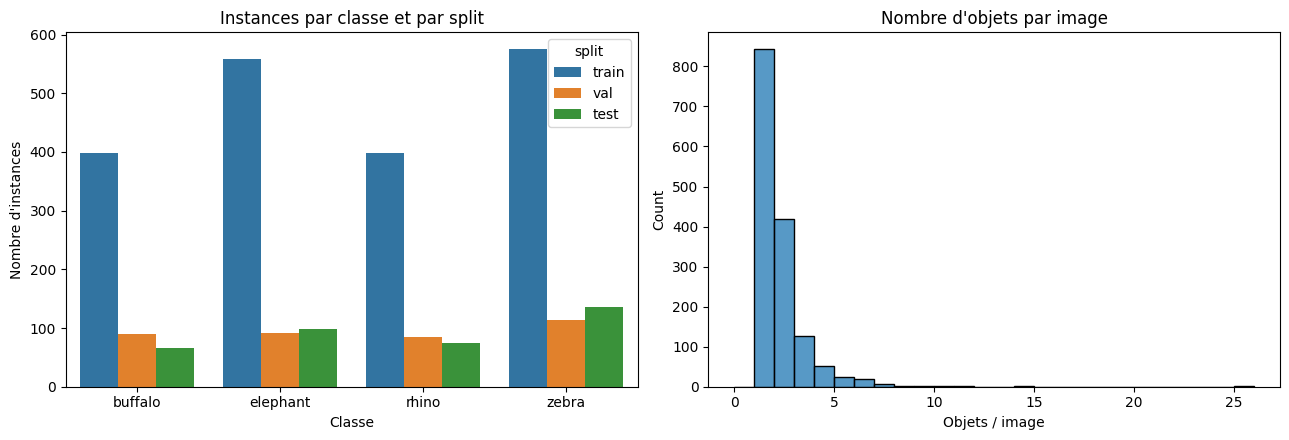

count    1504.00
mean        1.79
std         1.41
min         1.00
25%         1.00
50%         1.00
75%         2.00
max        25.00
Name: n_boxes, dtype: float64


In [17]:
counts = pd.crosstab(df["cls"], df["split"])[list(SPLITS.keys())]
counts["total"] = counts.sum(axis=1)
counts["% total"] = (counts["total"] / counts["total"].sum() * 100).round(1)
display(counts)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x="cls", hue="split", order=CLASSES, hue_order=list(SPLITS.keys()), ax=axes[0])
axes[0].set_title("Instances par classe et par split")
axes[0].set_xlabel("Classe"); axes[0].set_ylabel("Nombre d'instances")

sns.histplot(img["n_boxes"], bins=range(0, img["n_boxes"].max() + 2), ax=axes[1])
axes[1].set_title("Nombre d'objets par image"); axes[1].set_xlabel("Objets / image")
plt.tight_layout(); plt.show()

print(img["n_boxes"].describe().round(2))

### Résultats et explication
| Classe | Train | Val | Test | Total | % |
|---|---|---|---|---|---|
| buffalo | 399 | 89 | 66 | 554 | 20,6 |
| elephant | 558 | 91 | 99 | 748 | 27,9 |
| rhino | 399 | 85 | 75 | 559 | 20,8 |
| zebra | 575 | 114 | 135 | 824 | 30,7 |

- Le **déséquilibre est léger** : le zèbre est environ 1,5 fois plus fréquent que le buffle.
- Le **test contient seulement 66 buffles** : les résultats de cette classe seront moins stables.
- **Objets par image :** moyenne 1,79, médiane 1, maximum 25. La plupart des images ont 1 ou 2 animaux. Les **groupes denses sont rares**.

**À quoi ça sert ensuite ?** On saura interpréter les différences de mAP par classe. Les images à beaucoup d'animaux serviront à choisir les 8 scènes difficiles (étape 6, comptage).

# 7. Taille des bounding boxes

On mesure la taille des objets :
- **aire normalisée** = part de l'image occupée par l'objet (0 à 1),
- **aire en pixels**.

On les compare par classe avec des graphiques (boxplot, histogramme, largeur vs hauteur).

,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
buffalo,554.0,0.36082,0.25328,0.00754,0.13772,0.31915,0.57231,0.97703
elephant,748.0,0.22378,0.20670,0.00227,0.05162,0.17235,0.34255,0.99375
rhino,559.0,0.32548,0.20802,0.01290,0.15100,0.29728,0.45588,0.94348
zebra,824.0,0.21589,0.19722,0.00227,0.05941,0.14789,0.33753,0.85022


,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
buffalo,554.0,251413.0,406883.0,1035.0,27808.0,90601.0,267791.0,2355462.0
elephant,748.0,97580.0,172846.0,522.0,15054.0,50628.0,109701.0,1549491.0
rhino,559.0,204977.0,257138.0,990.0,50748.0,113131.0,258724.0,1851576.0
zebra,824.0,93893.0,167625.0,851.0,16177.0,43551.0,113083.0,1624051.0


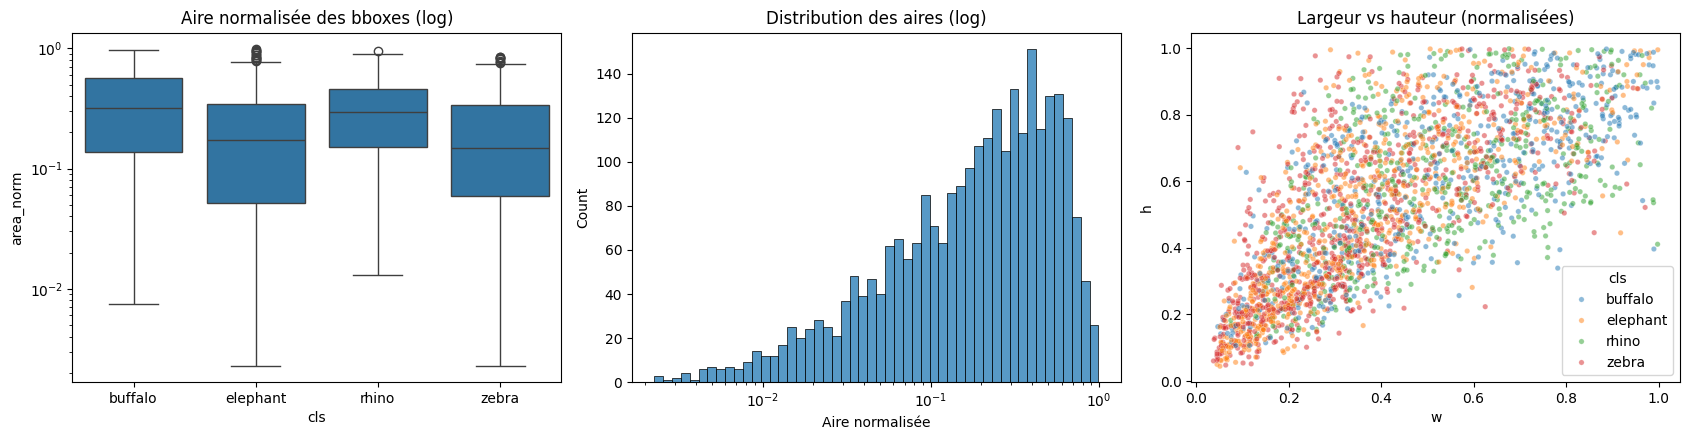

Part des objets dont l'aire < 1% de l'image   : 2.5 %
Part des objets dont l'aire < 0.1% de l'image : 0.0 %


In [18]:
display(df.groupby("cls")["area_norm"].describe().round(5))
display(df.groupby("cls")["area_px"].describe().round(0))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.boxplot(data=df, x="cls", y="area_norm", order=CLASSES, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_title("Aire normalisée des bboxes (log)")

sns.histplot(df["area_norm"], bins=50, log_scale=True, ax=axes[1])
axes[1].set_title("Distribution des aires (log)"); axes[1].set_xlabel("Aire normalisée")

sns.scatterplot(data=df.sample(min(len(df), 3000), random_state=SEED), x="w", y="h", hue="cls",
                hue_order=CLASSES, alpha=0.5, s=15, ax=axes[2])
axes[2].set_title("Largeur vs hauteur (normalisées)")
plt.tight_layout(); plt.show()

print("Part des objets dont l'aire < 1% de l'image   :", round((df["area_norm"] < 0.01).mean() * 100, 1), "%")
print("Part des objets dont l'aire < 0.1% de l'image :", round((df["area_norm"] < 0.001).mean() * 100, 1), "%")

### Résultats et explication
| Classe | Aire normalisée médiane |
|---|---|
| rhino | 0,297 (le plus grand) |
| elephant | 0,172 |
| zebra | 0,148 (le plus petit) |

- Seulement **2,5 %** des objets occupent moins de 1 % de l'image, et **0 %** moins de 0,1 %. Il n'y a donc **pas d'objets microscopiques**.
- Dans ce dataset, « petit objet » veut dire **petit par rapport aux autres objets**, pas petit au sens absolu (comme dans COCO).

**À quoi ça sert ensuite ?** C'est la base de la règle petit/grand et cela explique pourquoi les animaux éloignés sont plus difficiles pour YOLOv8n.

# 8. Règle petit / grand objet

**Règle choisie :** un objet est « **petit** » si son aire normalisée est **inférieure à la médiane de la validation**. Sinon il est « **grand** ».

**Pourquoi la médiane de la validation ?**
- Le cahier des charges demande de définir la règle **à partir de la validation**.
- On ne touche jamais au test pour choisir un paramètre : le test sert seulement à évaluer à la fin.
- La médiane donne deux groupes de même taille, donc assez d'exemples dans chaque groupe.

On calcule aussi le quartile Q25 comme **test de sensibilité** (seuil plus strict).

Seuil (médiane val) : aire_norm = 0.2271  ≈ boîte de 244×244 px à 512 px
Seuil Q25 (sensibilité) : 0.0773

Par split :


size,large,small
split,,
train,908,1023
val,190,189
test,182,193


Par classe (val) :


size,large,small
cls,,
buffalo,47,42
elephant,43,48
rhino,52,33
zebra,48,66


Par classe (test) :


size,large,small
cls,,
buffalo,45,21
elephant,47,52
rhino,46,29
zebra,44,91


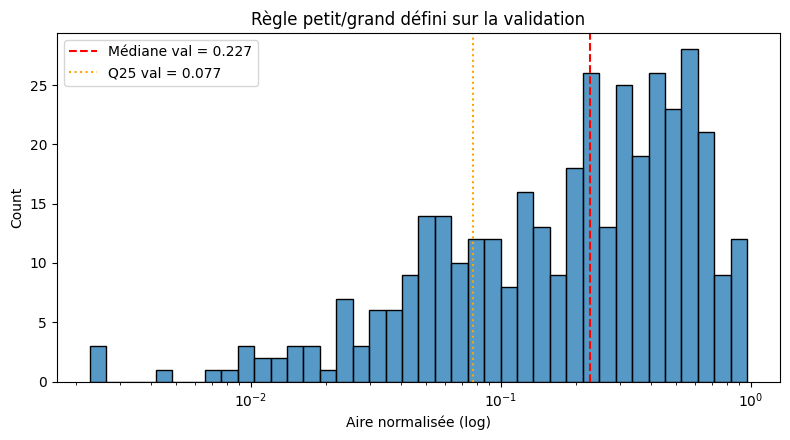

Sauvegardé dans /content/African_Wildlife_Detection_and_Counting_Project/results


In [19]:
val = df[df["split"] == "val"]

THR = float(val["area_norm"].median())
THR_Q25 = float(val["area_norm"].quantile(0.25))

df["size"] = np.where(df["area_norm"] < THR, "small", "large")

side = np.sqrt(THR) * 512
print(f"Seuil (médiane val) : aire_norm = {THR:.4f}  ≈ boîte de {side:.0f}×{side:.0f} px à 512 px")
print(f"Seuil Q25 (sensibilité) : {THR_Q25:.4f}")

print("\nPar split :")
display(pd.crosstab(df["split"], df["size"]).loc[list(SPLITS.keys())])

print("Par classe (val) :")
display(pd.crosstab(df.loc[df.split == "val", "cls"], df.loc[df.split == "val", "size"]))

print("Par classe (test) :")
display(pd.crosstab(df.loc[df.split == "test", "cls"], df.loc[df.split == "test", "size"]))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(val["area_norm"], bins=40, log_scale=True, ax=ax)
ax.axvline(THR, color="red", ls="--", label=f"Médiane val = {THR:.3f}")
ax.axvline(THR_Q25, color="orange", ls=":", label=f"Q25 val = {THR_Q25:.3f}")
ax.set_title("Règle petit/grand défini sur la validation")
ax.set_xlabel("Aire normalisée (log)"); ax.legend()
plt.tight_layout(); plt.show()

# ---- Sauvegarde pour toute l'équipe ----
df.to_csv(f"{OUT}/annotations_all.csv", index=False)
json.dump({"rule": "median of val bbox area_norm (w*h, YOLO normalized)",
           "threshold_area_norm": THR, "threshold_q25_sensitivity": THR_Q25,
           "small_if": "area_norm < threshold", "seed": SEED},
          open(f"{OUT}/size_rule.json", "w"), indent=2)
print("Sauvegardé dans", OUT)

### Résultats et explication
- **Seuil = 0,227** (médiane de la validation), soit environ une boîte de **244 × 244 px** à 512 px. Seuil de sensibilité Q25 = 0,077.

| Partition | Grands | Petits |
|---|---|---|
| Val | 190 | 189 |
| Test | 182 | 193 |

- La répartition est **équilibrée** et **presque identique sur le test** : la règle se transpose bien.
- **Zèbre :** 58 % de petits objets en validation. **Rhinocéros :** 39 %.
- **Attention :** comme le zèbre est plus souvent « petit », une différence de performance entre petits et grands objets peut venir de la **classe** et pas seulement de la **taille**. On l'écrira comme une limite dans le rapport.

**À quoi ça sert ensuite ?** C'est l'**étape 5** (Moussa) : calcul du rappel des petits et des grands objets pour les modèles A et B. Le fichier `annotations_all.csv` (avec la colonne `size`) et `size_rule.json` évitent de recalculer la règle et garantissent que toute l'équipe utilise le même seuil.

# 9. Exemples annotés

On affiche **12 images** du train (3 par classe) : un **petit**, un **moyen** et un **grand** objet pour chaque classe (percentiles 5 %, 50 % et 95 % de l'aire).

**Remarque :** le titre indique l'aire de l'objet choisi, mais l'image montre **toutes** les boîtes présentes dans l'image.

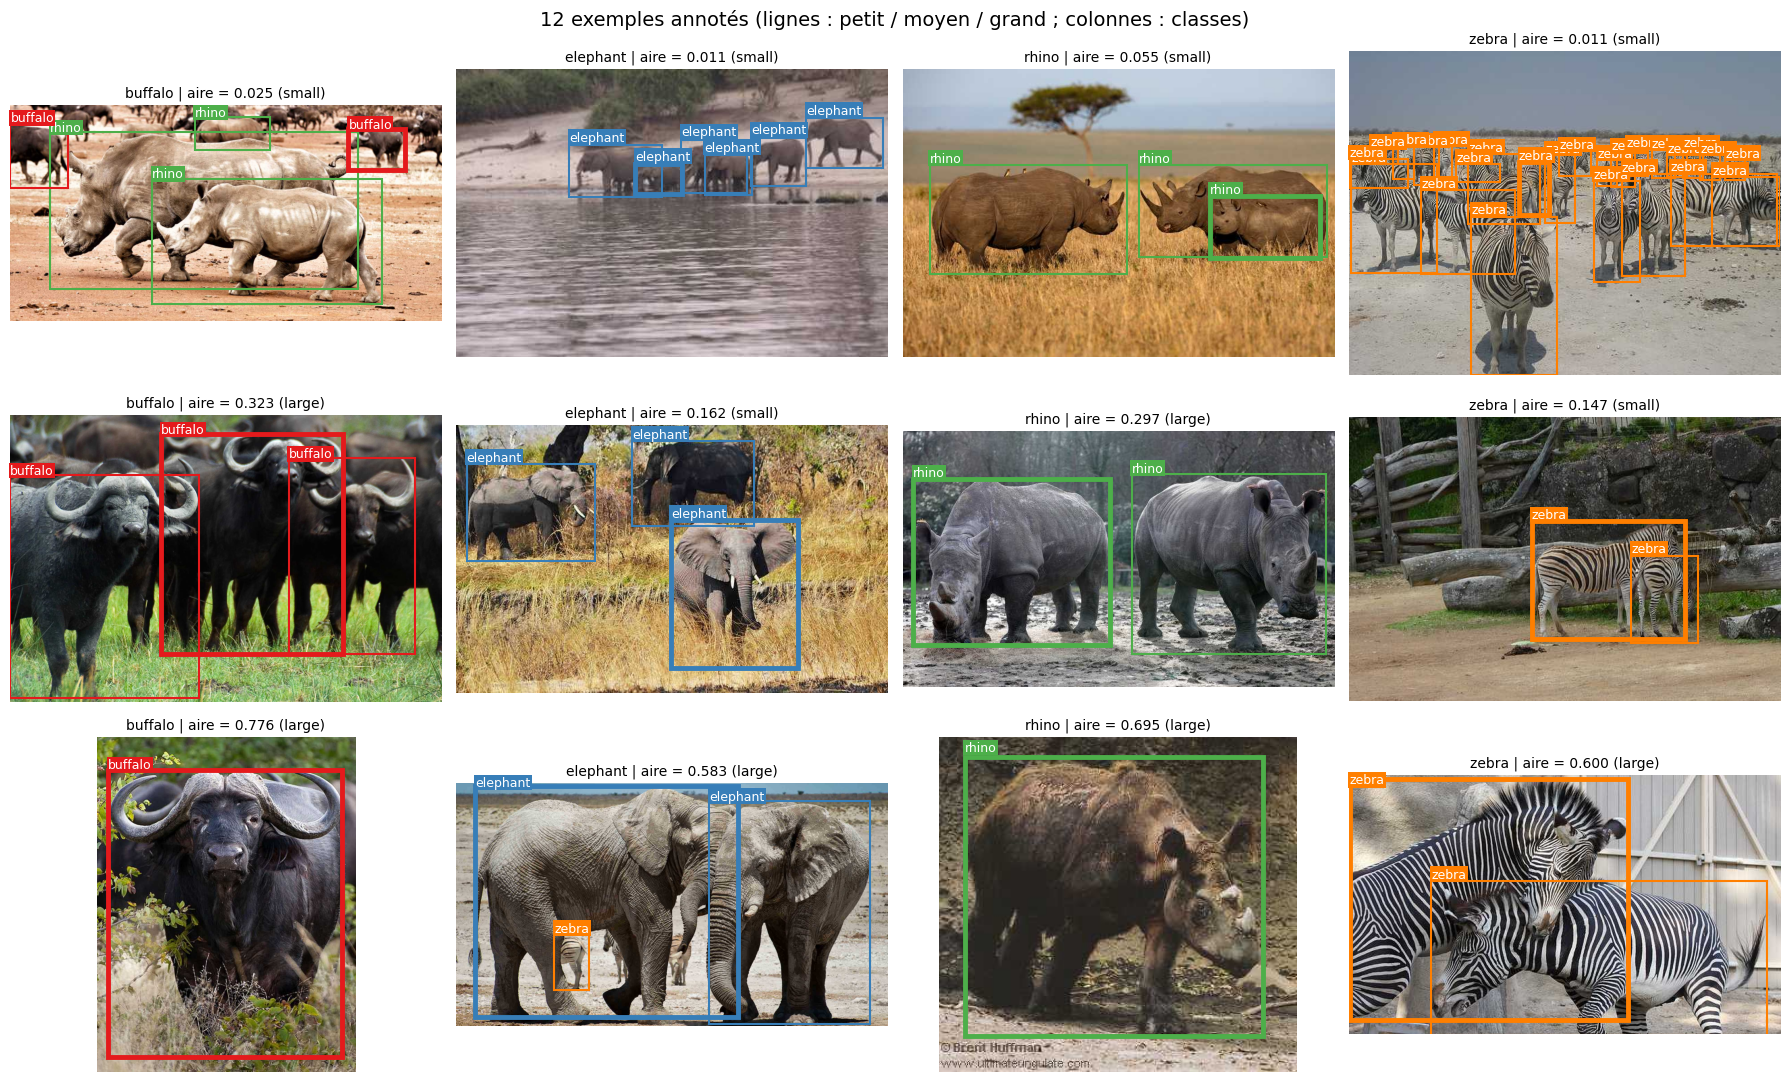

In [20]:
from matplotlib.patches import Rectangle

COLORS = {"buffalo": "#e41a1c", "elephant": "#377eb8", "rhino": "#4daf4a", "zebra": "#ff7f00"}

tr = df[df["split"] == "train"]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))

for ci, c in enumerate(CLASSES):
    sub = tr[tr["cls"] == c].sort_values("area_norm").reset_index(drop=True)
    for ri, q in enumerate((0.05, 0.50, 0.95)):          # petit, moyen, grand
        row = sub.iloc[int(q * (len(sub) - 1))]
        ax = axes[ri, ci]
        ax.imshow(Image.open(f"{ROOT}/images/{SPLITS['train']}/{row['image']}"))
        for _, b in tr[tr["image"] == row["image"]].iterrows():
            x1 = (b["xc"] - b["w"] / 2) * b["W"]
            y1 = (b["yc"] - b["h"] / 2) * b["H"]
            chosen = abs(b["area_norm"] - row["area_norm"]) < 1e-9
            ax.add_patch(Rectangle((x1, y1), b["w"] * b["W"], b["h"] * b["H"], fill=False,
                                   edgecolor=COLORS[b["cls"]], lw=3.5 if chosen else 1.5))
            ax.text(x1, max(y1 - 5, 12), b["cls"], color="white", fontsize=9,
                    bbox=dict(facecolor=COLORS[b["cls"]], pad=1, edgecolor="none"))
        ax.set_title(f"{c} | aire = {row['area_norm']:.3f} ({row['size']})", fontsize=10)
        ax.axis("off")

plt.suptitle("12 exemples annotés (lignes : petit / moyen / grand ; colonnes : classes)", fontsize=14)
plt.tight_layout()
plt.savefig(f"{OUT}/12_exemples_annotes.png", dpi=150, bbox_inches="tight")
plt.show()

### Observations
- Les boîtes sont **bien placées** sur les animaux : cela confirme visuellement la bonne qualité des annotations.
- **Scènes multi-espèces :** par exemple des rhinocéros et des buffles dans la même image.
- **Groupes denses et chevauchements :** des zèbres très serrés (jusqu'à environ 25 objets dans une image).
- **Animaux éloignés :** des éléphants dans l'eau ou des zèbres au loin (aire d'environ 0,011).

**À quoi ça sert ensuite ?** Ces cas difficiles guideront le choix des **8 scènes difficiles** (étape 6) et l'explication des erreurs de comptage. Cette figure sera aussi utilisée dans le rapport et la présentation orale.

# 10. Conclusion de l'Étape 1

Le dataset **African Wildlife** est **complet et de bonne qualité** : 1 504 images, 2 685 boîtes, aucune anomalie, partitions officielles respectées (1 052 / 225 / 227).

Les 4 classes sont **assez équilibrées** (zèbre 30,7 % à buffle 20,6 %). Il y a peu d'objets par image (médiane 1, maximum 25), donc les groupes denses sont rares.

Les objets sont petits **relativement** (aire médiane entre 0,148 et 0,297), rarement minuscules.

Nous avons défini une **règle petit/grand sur la validation uniquement** (seuil 0,227), qui donne une répartition équilibrée et se transpose bien sur le test.

**Limites :**
- peu de buffles dans le test (66), donc des résultats moins stables pour cette classe ;
- le zèbre est plus souvent « petit » que le rhinocéros, donc taille et classe peuvent se mélanger dans l'analyse ;
- les images ont des résolutions différentes, ce qui pénalise les animaux lointains après redimensionnement.

**Fichiers produits (Drive) :** `annotations_all.csv`, `size_rule.json`, `12_exemples_annotes.png`.

## À quoi sert cette étape pour la suite du projet ?

| Étape suivante | Ce qu'on utilise de l'Étape 1 |
|---|---|
| Étape 2 – Modèle A | Les partitions officielles et les 4 classes |
| Étape 3 – Modèle B | Les mêmes partitions, pour une comparaison juste avec A |
| Étape 4 – Seuils confiance / NMS | La validation (225 images), sur laquelle on choisit les seuils |
| Étape 5 – Petits vs grands | La règle (seuil 0,227) et le fichier `annotations_all.csv` |
| Étape 6 – Comptage et scènes difficiles | Les groupes denses, les scènes multi-espèces et les animaux éloignés |
| Rapport final | Les statistiques, les graphiques, les limites et les 12 exemples |

# 11. Envoi des résultats vers GitHub

**Objectif :** mettre les résultats de l'Étape 1 dans le dépôt du projet, pour que toute l'équipe puisse les utiliser sans passer par Google Drive.

**Fichiers envoyés (dossier `results/`) :**
- `annotations_all.csv` : toutes les boîtes, avec la colonne `size` (petit / grand)
- `size_rule.json` : la règle petit/grand (seuil 0,227)
- `12_exemples_annotes.png` : la figure des 12 exemples



In [23]:
import os, subprocess
from getpass import getpass

# ================== À MODIFIER SI BESOIN ==================
GIT_NAME  = "Rachida LEMNAOUIR"
GIT_EMAIL = "rachida.lemnaouir@usmba.ac.ma"
BRANCH    = "dataset-exploration"
REPO_SLUG = "YSSFM/African_Wildlife_Detection_and_Counting_Project"
FILES = ["results/annotations_all.csv",
         "results/size_rule.json",
         "results/12_exemples_annotes.png"]
# ===========================================================

try:
    REPO_DIR
except NameError:
    REPO_DIR = "/content/African_Wildlife_Detection_and_Counting_Project"
if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", "-q", f"https://github.com/{REPO_SLUG}.git", REPO_DIR], check=True)

# ---- Token  ----
try:
    from google.colab import userdata
    TOKEN = userdata.get("GITHUB_TOKEN")
except Exception:
    TOKEN = getpass("Colle ton token GitHub (il ne s'affichera pas) : ")
TOKEN = (TOKEN or "").strip()
assert TOKEN, "Token vide."

ENV = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}

def git(*args, show=True):
    """Lance git dans le dépôt. Le token est masqué dans l'affichage."""
    r = subprocess.run(["git", *args], cwd=REPO_DIR, capture_output=True, text=True, env=ENV)
    out = (r.stdout + r.stderr).replace(TOKEN, "***").strip()
    if show:
        label = " ".join(a if TOKEN not in a else "<url>" for a in args[:2])
        print(f"$ git {label}\n{out}\n")
    return r

# 1. Les fichiers existent ?
missing = [f for f in FILES if not os.path.exists(f"{REPO_DIR}/{f}")]
if missing:
    raise FileNotFoundError(f"Fichiers manquants (relance les sections 8 et 9) : {missing}")

# 2. Ils ne sont pas bloqués par .gitignore ?
for f in FILES:
    if git("check-ignore", "-q", f, show=False).returncode == 0:
        raise RuntimeError(f"{f} est ignoré par .gitignore. Ajoute dans .gitignore la ligne : !{f}")

# 3. Identité, branche, commit
git("config", "user.name", GIT_NAME)
git("config", "user.email", GIT_EMAIL)
git("checkout", "-B", BRANCH)
git("add", *FILES)
git("commit", "-m", "Étape 1 : exploration du dataset, règle petit/grand (seuil 0.227)")

# 4. Push
r = git("push", "-u", f"https://{TOKEN}@github.com/{REPO_SLUG}.git", BRANCH)

if r.returncode == 0:
    print("✅ Envoyé ! Ouvre la Pull Request ici :")
    print(f"https://github.com/{REPO_SLUG}/pull/new/{BRANCH}")
else:
    print("❌ Push échoué : lis le message ci-dessus.")

Colle ton token GitHub (il ne s'affichera pas) : ··········
$ git config user.name


$ git config user.email


$ git checkout -B
Switched to a new branch 'dataset-exploration'

$ git add results/annotations_all.csv


$ git commit -m
[dataset-exploration c223b65] Étape 1 : exploration du dataset, règle petit/grand (seuil 0.227)
 3 files changed, 2693 insertions(+)
 create mode 100644 results/12_exemples_annotes.png
 create mode 100644 results/annotations_all.csv
 create mode 100644 results/size_rule.json

$ git push -u
branch 'dataset-exploration' set up to track 'https://***@github.com/YSSFM/African_Wildlife_Detection_and_Counting_Project.git/dataset-exploration'.
remote: 
remote: Create a pull request for 'dataset-exploration' on GitHub by visiting:        
remote:      https://github.com/YSSFM/African_Wildlife_Detection_and_Counting_Project/pull/new/dataset-exploration        
remote: 
To https://github.com/YSSFM/African_Wildlife_Detection_and_Counting_Project.git
 * [new branch]    